# 06 — Model fitting

Models here measure **which pre-release attributes matter**; they are not
the point of the project. Three targets on the financial sample:

- `log1p(revenue)` in constant 2025 dollars (regression)
- `log(ROI)` (regression) — deflation cancels in the ratio
- `is_profitable` (classification)

**Honesty rules.** The train/test split is **by release year**, not
random: models are evaluated on films they could not have seen. All
imputation and scaling happens inside a `Pipeline`/`ColumnTransformer`
fitted on the training years only. Post-release variables (votes,
popularity) are excluded — Chapter 4 showed the leakage they carry. The
class balance is reported, and accuracy is never reported alone.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats as sps
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve, root_mean_squared_error, r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan

from src.features import BINARY_PREDICTORS, CATEGORICAL_PREDICTORS, NUMERIC_PREDICTORS
from src.load import load_processed
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_processed("movies_features")
fin = df[df["has_financials"] & ~df["is_future"]].copy()
fin = fin.dropna(subset=["Budget_2025usd", "Revenue_2025usd"])  # 1910s films without CPI
fin["log_revenue"] = np.log1p(fin["Revenue_2025usd"].astype("float64"))
fin["log_roi"] = np.log(fin["roi"].astype("float64"))
fin["log_budget_2025"] = np.log1p(fin["Budget_2025usd"].astype("float64"))
stats["n_model"] = len(fin)
print(f"modelling sample: {len(fin):,} films (complete financials, released <= 2025, CPI available)")

modelling sample: 6,560 films (complete financials, released <= 2025, CPI available)


## Train/test split by release year

The threshold is the 80th percentile of release years, so the test set is
the most recent fifth of films — the setting a studio actually faces:
predict the next years from the past.

In [2]:
split_year = int(fin["Release_Year"].astype("float64").quantile(0.8))
train = fin[fin["Release_Year"].astype("float64") <= split_year]
test = fin[fin["Release_Year"].astype("float64") > split_year]
stats.update(split_year=split_year, n_train=len(train), n_test=len(test))
print(f"train: {len(train):,} films (<= {split_year})   test: {len(test):,} films ({split_year + 1}–2025)")

train: 5,431 films (<= 2017)   test: 1,129 films (2018–2025)


## Features and preprocessing

The Chapter 4 feature set. `Release_Year` is dropped from the predictors
for the year-split models: with the test set strictly later than every
training film, a year coefficient would extrapolate outside its support
and silently absorb the split itself. `genre_count` is absent because it
is the exact sum of the genre flags (Chapter 4).

In [3]:
numeric = [c for c in NUMERIC_PREDICTORS if c not in ("Budget_2025usd", "Release_Year")] + ["log_budget_2025"]
binary = list(BINARY_PREDICTORS)
categorical = list(CATEGORICAL_PREDICTORS)
genre_cols = sorted(c for c in fin.columns if c.startswith("genre_") and c != "genre_count")
feature_cols = numeric + binary + genre_cols + categorical

def Xy(frame, target):
    X = frame[feature_cols].copy()
    for c in numeric:
        X[c] = X[c].astype("float64")
    for c in binary + genre_cols:
        X[c] = X[c].astype("float64")
    return X, frame[target].astype("float64" if target != "is_profitable" else "bool")

prep = ColumnTransformer(
    [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric),
        ("bin", "passthrough", binary + genre_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", drop="first"))]), categorical),
    ],
    verbose_feature_names_out=False,
)
print(f"{len(feature_cols)} input columns")

29 input columns


## Target 1 — log1p(revenue), constant 2025 dollars

### OLS on the interpretable set

Fitted with statsmodels on the training years, numerics in natural units
(log budget keeps an elasticity reading: its coefficient is the % change
in revenue per 1% change in budget).

In [4]:
def ols_matrix(frame, med=None):
    X = frame[numeric + binary + genre_cols].copy()
    for c in X.columns:
        X[c] = X[c].astype("float64")
    X["debut_director"] = X["director_mean_prior_rating"].isna().astype(float)
    if med is None:
        med = X.median(numeric_only=True)
    X = X.fillna(med)
    tiers = pd.get_dummies(frame["studio_tier"], prefix="tier", drop_first=True).astype(float)
    X = pd.concat([X, tiers], axis=1)
    return sm.add_constant(X, has_constant="add"), med

X_tr_ols, med_tr = ols_matrix(train)
# Drop columns that are (near-)constant in the training years — they make
# the design matrix rank-deficient. Reported, not silent.
counts = (X_tr_ols.drop(columns="const") != 0).sum()
degenerate = counts[counts < 10].index.tolist()
if degenerate:
    print(f"dropped from OLS (fewer than 10 non-zero training rows): {degenerate}")
    X_tr_ols = X_tr_ols.drop(columns=degenerate)
stats["ols_dropped_degenerate"] = ", ".join(degenerate) if degenerate else "none"
X_te_ols, _ = ols_matrix(test, med_tr)
X_te_ols = X_te_ols.reindex(columns=X_tr_ols.columns, fill_value=0.0)
y_tr = train["log_revenue"]
y_te = test["log_revenue"]

ols = sm.OLS(y_tr, X_tr_ols).fit()
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, X_tr_ols)
stats["ols_rev_r2_train"] = round(float(ols.rsquared), 3)
stats["ols_rev_r2_test"] = round(float(r2_score(y_te, ols.predict(X_te_ols))), 3)
stats["ols_bp_p"] = float(bp_p)
print(f"Breusch-Pagan p = {bp_p:.2e} -> heteroscedastic, so inference below uses HC3 robust errors")

ols_r = sm.OLS(y_tr, X_tr_ols).fit(cov_type="HC3")
coef = pd.DataFrame({"coef": ols_r.params, "p (HC3)": ols_r.pvalues}).drop(index="const")
ci_all = ols_r.conf_int().drop(index="const")
coef["ci_lo"], coef["ci_hi"] = ci_all[0], ci_all[1]
top_coef = coef.reindex(coef["coef"].abs().sort_values(ascending=False).index).head(15)

coef_tex = top_coef.reset_index(names="term")
coef_tex = pd.DataFrame(
    {
        "term": coef_tex["term"],
        "coefficient": coef_tex["coef"].map(lambda v: f"{v:+.3f}"),
        "95% CI (HC3)": [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(coef_tex["ci_lo"], coef_tex["ci_hi"])],
        "p (HC3)": coef_tex["p (HC3)"].map(fmt_p),
    }
)
write_table(coef_tex, "tab5_1_ols_revenue_coefs", align="lrrr")
for term in ["tier_major", "tier_mid", "is_holiday_release", "is_summer_release", "is_english",
             "genre_documentary", "genre_animation", "genre_horror", "director_mean_prior_rating", "Runtime_Mins"]:
    if term in ols_r.params:
        stats[f"ols_coef_{term.lower()}"] = round(float(ols_r.params[term]), 3)
        stats[f"ols_p_{term.lower()}"] = float(ols_r.pvalues[term])
top_coef[["coef", "p (HC3)"]].round(3)

dropped from OLS (fewer than 10 non-zero training rows): ['genre_tv_movie']


Breusch-Pagan p = 3.94e-75 -> heteroscedastic, so inference below uses HC3 robust errors


,coef,p (HC3)
genre_documentary,0.871,0.001
log_budget_2025,0.698,0.000
tier_major,0.692,0.000
genre_western,-0.470,0.011
genre_drama,-0.392,0.000
tier_mid,0.360,0.000
genre_animation,0.329,0.000
genre_history,-0.256,0.003
genre_family,0.255,0.000
genre_science_fiction,-0.250,0.000


In [5]:
stats["ols_budget_elasticity"] = round(float(ols_r.params["log_budget_2025"]), 3)
stats["ols_budget_p"] = float(ols_r.pvalues["log_budget_2025"])
ci = ols_r.conf_int().loc["log_budget_2025"]
stats["ols_budget_ci_lo"] = round(float(ci[0]), 3)
stats["ols_budget_ci_hi"] = round(float(ci[1]), 3)
print(f"budget elasticity: {ols_r.params['log_budget_2025']:.3f} "
      f"[95% CI {ci[0]:.3f}, {ci[1]:.3f}], p = {ols_r.pvalues['log_budget_2025']:.1e}")
print(f"train R^2 = {stats['ols_rev_r2_train']}, test R^2 = {stats['ols_rev_r2_test']} (n test = {len(test):,})")

budget elasticity: 0.698 [95% CI 0.644, 0.752], p = 3.7e-141
train R^2 = 0.456, test R^2 = 0.361 (n test = 1,129)


### OLS diagnostics

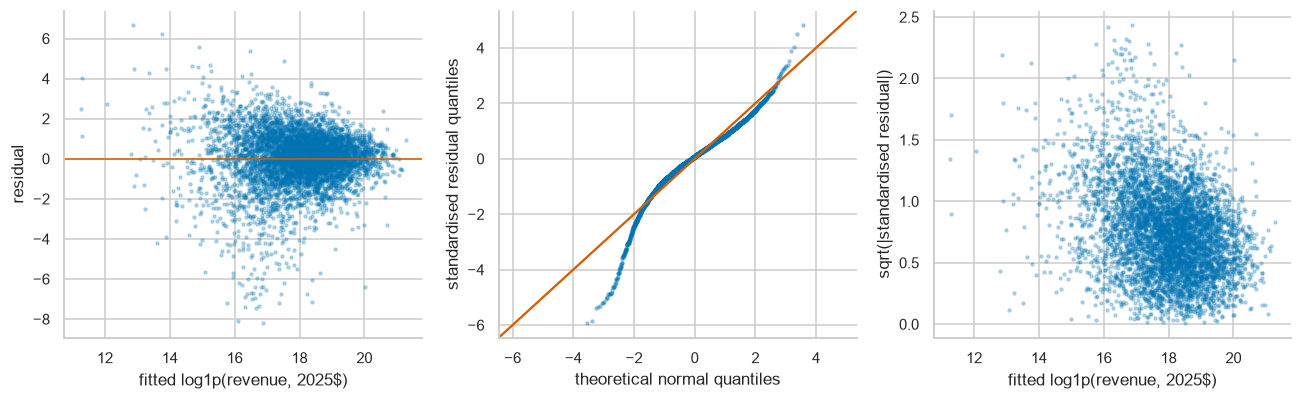

In [6]:
fitted = ols.fittedvalues
resid = ols.resid
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].scatter(fitted, resid, s=4, alpha=0.25)
axes[0].axhline(0, color="C3", lw=1)
axes[0].set_xlabel("fitted log1p(revenue, 2025$)")
axes[0].set_ylabel("residual")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=0.3)
axes[1].set_xlabel("theoretical normal quantiles")
axes[1].set_ylabel("standardised residual quantiles")
axes[2].scatter(fitted, np.sqrt(np.abs(resid / resid.std())), s=4, alpha=0.25)
axes[2].set_xlabel("fitted log1p(revenue, 2025$)")
axes[2].set_ylabel("sqrt(|standardised residual|)")
fig.tight_layout()
save_fig(fig, "fig5_1_ols_diagnostics")
stats["ols_resid_skew"] = round(float(sps.skew(resid)), 2)
plt.show()

Residuals fan out at the low-fitted end and the Q-Q plot shows a heavy
left tail: the model misses worst on films that earned far *less* than
their attributes suggest — flops are idiosyncratic. Heteroscedasticity is
confirmed by Breusch-Pagan, hence the HC3 robust standard errors above.

### Regularised and gradient-boosted comparisons

Ridge (alpha chosen by cross-validation inside the training years) and a
histogram gradient-boosted tree, both through the same leakage-safe
preprocessing. The boosted tree is the ceiling check: how much signal is
there beyond the linear fit?

In [7]:
X_tr, _ = Xy(train, "log_revenue")
X_te, _ = Xy(test, "log_revenue")

results = {}
models = {
    "OLS": None,  # filled from statsmodels above
    "Ridge": Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
    "HistGB": Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]),
}
results["OLS"] = {
    "test_R2": stats["ols_rev_r2_test"],
    "test_RMSE": round(float(root_mean_squared_error(y_te, ols.predict(X_te_ols))), 3),
}
for name, pipe in models.items():
    if pipe is None:
        continue
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    results[name] = {
        "test_R2": round(float(r2_score(y_te, pred)), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te, pred)), 3),
    }
rev_results = pd.DataFrame(results).T
stats["ridge_rev_r2_test"] = float(rev_results.loc["Ridge", "test_R2"])
stats["gb_rev_r2_test"] = float(rev_results.loc["HistGB", "test_R2"])
stats["ols_rev_rmse_test"] = float(rev_results.loc["OLS", "test_RMSE"])
stats["ridge_rev_rmse_test"] = float(rev_results.loc["Ridge", "test_RMSE"])
rev_results

,test_R2,test_RMSE
OLS,0.361,1.716
Ridge,0.381,1.689
HistGB,0.364,1.712


## Target 2 — log(ROI)

Identical protocol, second target. Chapter 4's mutual information already
said this signal is weaker; here is how much weaker.

In [8]:
y_tr_roi = train["log_roi"]
y_te_roi = test["log_roi"]

ols_roi = sm.OLS(y_tr_roi, X_tr_ols).fit(cov_type="HC3")
roi_results = {
    "OLS": {
        "test_R2": round(float(r2_score(y_te_roi, ols_roi.predict(X_te_ols))), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te_roi, ols_roi.predict(X_te_ols))), 3),
    }
}
for name, maker in {
    "Ridge": lambda: Pipeline([("prep", prep), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
    "HistGB": lambda: Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]),
}.items():
    pipe = maker()
    pipe.fit(X_tr, y_tr_roi)
    pred = pipe.predict(X_te)
    roi_results[name] = {
        "test_R2": round(float(r2_score(y_te_roi, pred)), 3),
        "test_RMSE": round(float(root_mean_squared_error(y_te_roi, pred)), 3),
    }
roi_results = pd.DataFrame(roi_results).T
stats["ols_roi_r2_test"] = float(roi_results.loc["OLS", "test_R2"])
stats["gb_roi_r2_test"] = float(roi_results.loc["HistGB", "test_R2"])
stats["roi_budget_coef"] = round(float(ols_roi.params["log_budget_2025"]), 3)
stats["roi_budget_p"] = float(ols_roi.pvalues["log_budget_2025"])
stats["ridge_roi_r2_test"] = float(roi_results.loc["Ridge", "test_R2"])
ci_roi = ols_roi.conf_int().loc["log_budget_2025"]
stats["roi_budget_ci_lo"] = round(float(ci_roi[0]), 3)
stats["roi_budget_ci_hi"] = round(float(ci_roi[1]), 3)

cmp_tex = pd.DataFrame(
    {
        "model": ["OLS", "Ridge (CV alpha)", "Gradient-boosted tree"],
        "R² log1p(revenue)": [f"{v:.3f}" for v in rev_results["test_R2"]],
        "RMSE log1p(revenue)": [f"{v:.3f}" for v in rev_results["test_RMSE"]],
        "R² log(ROI)": [f"{v:.3f}" for v in roi_results["test_R2"]],
        "RMSE log(ROI)": [f"{v:.3f}" for v in roi_results["test_RMSE"]],
    }
)
cmp_tex.columns = ["model", "$R^2$ revenue", "RMSE revenue", "$R^2$ ROI", "RMSE ROI"]
write_table(cmp_tex, "tab5_2_regression_comparison")
roi_results

,test_R2,test_RMSE
OLS,0.031,1.716
Ridge,0.061,1.689
HistGB,0.042,1.706


In [9]:
print(f"budget coefficient on log(ROI): {ols_roi.params['log_budget_2025']:.3f} "
      f"(p = {ols_roi.pvalues['log_budget_2025']:.1e})")

budget coefficient on log(ROI): -0.302 (p = 6.2e-28)


### Predicted vs actual, both targets

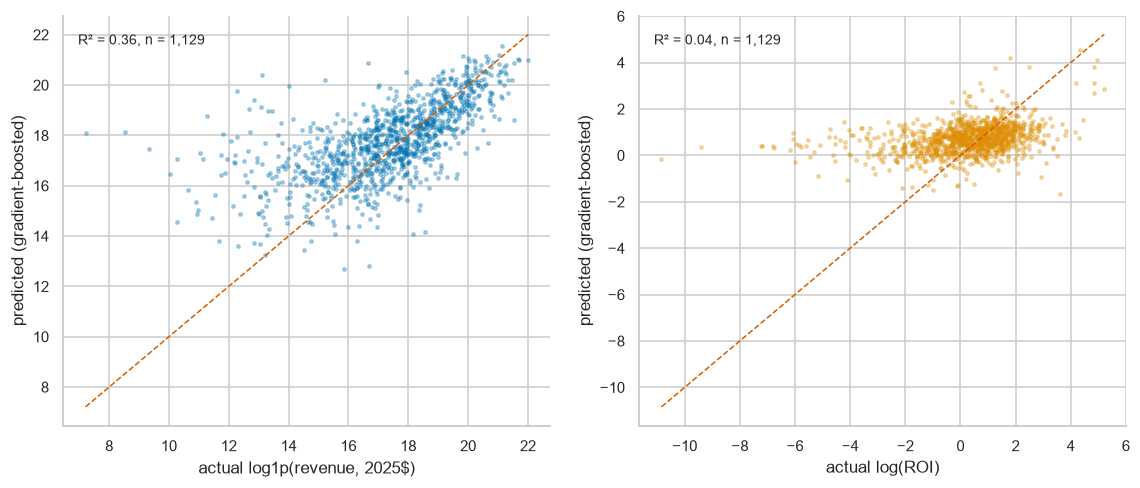

In [10]:
gb_rev = models["HistGB"]
pred_rev = gb_rev.predict(X_te)
gb_roi = Pipeline([("prep", prep), ("m", HistGradientBoostingRegressor(random_state=0))]).fit(X_tr, y_tr_roi)
pred_roi = gb_roi.predict(X_te)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
axes[0].scatter(y_te, pred_rev, s=5, alpha=0.3)
lims = [min(y_te.min(), pred_rev.min()), max(y_te.max(), pred_rev.max())]
axes[0].plot(lims, lims, color="C3", lw=1, ls="--")
axes[0].set_xlabel("actual log1p(revenue, 2025$)")
axes[0].set_ylabel("predicted (gradient-boosted)")
axes[0].annotate(f"R² = {stats['gb_rev_r2_test']:.2f}, n = {len(test):,}",
                 xy=(0.03, 0.93), xycoords="axes fraction", fontsize=9)
axes[1].scatter(y_te_roi, pred_roi, s=5, alpha=0.3, color="C1")
lims = [y_te_roi.min(), y_te_roi.max()]
axes[1].plot(lims, lims, color="C3", lw=1, ls="--")
axes[1].set_xlabel("actual log(ROI)")
axes[1].set_ylabel("predicted (gradient-boosted)")
axes[1].annotate(f"R² = {stats['gb_roi_r2_test']:.2f}, n = {len(test):,}",
                 xy=(0.03, 0.93), xycoords="axes fraction", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig5_2_pred_vs_actual")
plt.show()

## Target 3 — is_profitable (classification)

In [11]:
y_tr_c = train["is_profitable"].astype(bool)
y_te_c = test["is_profitable"].astype(bool)
stats["class_balance_train"] = round(float(y_tr_c.mean()) * 100, 1)
stats["class_balance_test"] = round(float(y_te_c.mean()) * 100, 1)
print(f"class balance (profitable): train {stats['class_balance_train']}%, test {stats['class_balance_test']}%")
print("-> a majority-class guesser already gets that accuracy; it is not reported as a result")

clf_results = {}
clfs = {
    "Logistic": Pipeline([("prep", prep), ("m", LogisticRegression(max_iter=2000))]),
    "HistGB": Pipeline([("prep", prep), ("m", HistGradientBoostingClassifier(random_state=0))]),
}
rocs = {}
for name, pipe in clfs.items():
    pipe.fit(X_tr, y_tr_c)
    prob = pipe.predict_proba(X_te)[:, 1]
    pred = prob >= 0.5
    clf_results[name] = {
        "precision": round(float(precision_score(y_te_c, pred)), 3),
        "recall": round(float(recall_score(y_te_c, pred)), 3),
        "F1": round(float(f1_score(y_te_c, pred)), 3),
        "ROC-AUC": round(float(roc_auc_score(y_te_c, prob)), 3),
    }
    rocs[name] = roc_curve(y_te_c, prob)
clf_results = pd.DataFrame(clf_results).T
stats["clf_best_auc"] = float(clf_results["ROC-AUC"].max())
stats["clf_best_f1"] = float(clf_results["F1"].max())

# The honest yardstick: a classifier that says "profitable" for every film
pred_all_true = np.ones(len(y_te_c), dtype=bool)
stats["majority_baseline_f1"] = round(float(f1_score(y_te_c, pred_all_true)), 3)
print(f"majority-baseline F1 (predict 'profitable' always): {stats['majority_baseline_f1']}")
print("-> F1 barely beats that baseline; the evidence of real ranking skill is the AUC")
for name in clf_results.index:
    for metric in ["precision", "recall"]:
        stats[f"clf_{name.lower()}_{metric}"] = float(clf_results.loc[name, metric])
    stats[f"clf_{name.lower()}_auc"] = float(clf_results.loc[name, "ROC-AUC"])
    stats[f"clf_{name.lower()}_f1"] = float(clf_results.loc[name, "F1"])

clf_tex = clf_results.reset_index(names="model")
clf_tex.loc[len(clf_tex)] = ["Always 'profitable' (baseline)", float(y_te_c.mean()), 1.0,
                             stats["majority_baseline_f1"], 0.5]
for c in ["precision", "recall", "F1", "ROC-AUC"]:
    clf_tex[c] = clf_tex[c].map(lambda v: f"{v:.3f}")
clf_tex["model"] = clf_tex["model"].replace({"Logistic": "Logistic regression",
                                             "HistGB": "Gradient-boosted tree"})
write_table(clf_tex, "tab5_3_classification")
clf_results

class balance (profitable): train 75.4%, test 63.9%
-> a majority-class guesser already gets that accuracy; it is not reported as a result


majority-baseline F1 (predict 'profitable' always): 0.779
-> F1 barely beats that baseline; the evidence of real ranking skill is the AUC


,precision,recall,F1,ROC-AUC
Logistic,0.647,0.990,0.783,0.682
HistGB,0.659,0.956,0.780,0.643


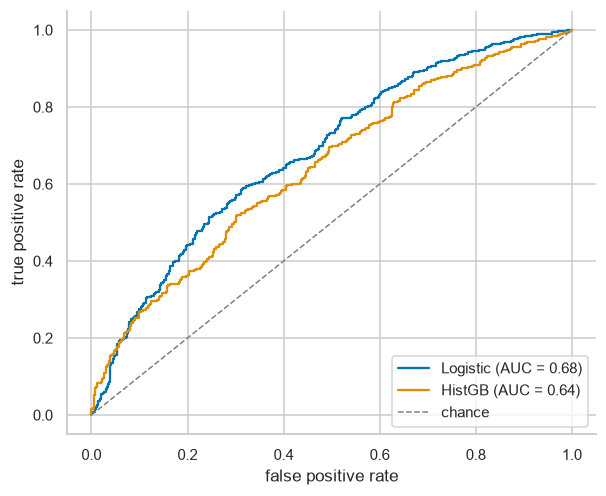

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for name, (fpr, tpr, _) in rocs.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC = {clf_results.loc[name, 'ROC-AUC']:.2f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.legend(loc="lower right")
save_fig(fig, "fig5_3_roc")
plt.show()

## Which features matter — permutation importance

Importance on the held-out years for the gradient-boosted revenue model:
how much test R² is lost when each feature is shuffled.

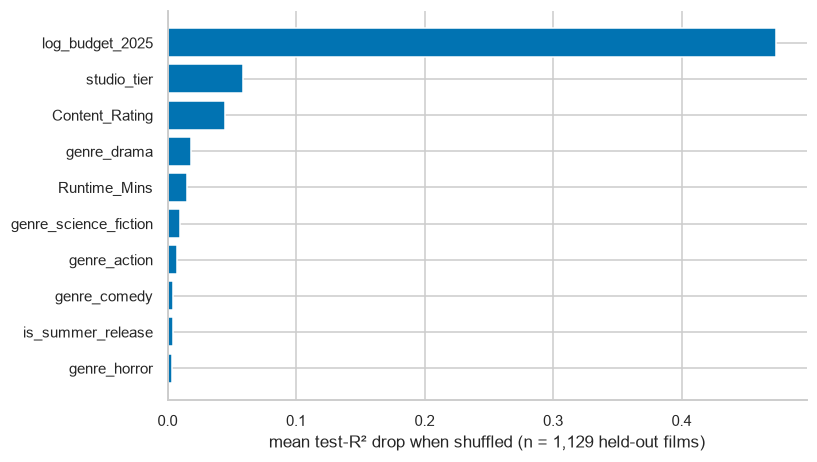

log_budget_2025          0.474
studio_tier              0.058
Content_Rating           0.045
genre_drama              0.018
Runtime_Mins             0.015
genre_science_fiction    0.010
genre_action             0.007
genre_comedy             0.004
is_summer_release        0.004
genre_horror             0.004
dtype: float64

In [13]:
pi = permutation_importance(gb_rev, X_te, y_te, n_repeats=10, random_state=0, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
stats["perm_top_feature"] = str(imp.index[0])
stats["perm_top_drop"] = round(float(imp.iloc[0]), 3)
stats["perm_second_drop"] = round(float(imp.iloc[1]), 3)
stats["perm_second_feature"] = str(imp.index[1])

top10 = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top10.index, top10.values, color="C0")
ax.set_xlabel(f"mean test-R² drop when shuffled (n = {len(test):,} held-out films)")
save_fig(fig, "fig5_4_permutation_importance")
plt.show()
imp.head(10).round(3)

In [14]:
out = write_stats("ch05_modelling", stats)
print(f"{len(stats)} statistics -> {out.relative_to(ROOT)}")
stats

61 statistics -> report\stats\ch05_modelling.json


{'n_model': 6560,
 'split_year': 2017,
 'n_train': 5431,
 'n_test': 1129,
 'ols_dropped_degenerate': 'genre_tv_movie',
 'ols_rev_r2_train': 0.456,
 'ols_rev_r2_test': 0.361,
 'ols_bp_p': 3.938224320379909e-75,
 'ols_coef_tier_major': 0.692,
 'ols_p_tier_major': 5.08339259149509e-46,
 'ols_coef_tier_mid': 0.36,
 'ols_p_tier_mid': 7.238166303752706e-12,
 'ols_coef_is_holiday_release': 0.234,
 'ols_p_is_holiday_release': 2.098218878819932e-06,
 'ols_coef_is_summer_release': 0.198,
 'ols_p_is_summer_release': 3.386404645773045e-05,
 'ols_coef_is_english': 0.224,
 'ols_p_is_english': 0.005742604954605668,
 'ols_coef_genre_documentary': 0.871,
 'ols_p_genre_documentary': 0.0011506242145084935,
 'ols_coef_genre_animation': 0.329,
 'ols_p_genre_animation': 0.00027256429471265314,
 'ols_coef_genre_horror': -0.108,
 'ols_p_genre_horror': 0.18171121401355095,
 'ols_coef_director_mean_prior_rating': 0.128,
 'ols_p_director_mean_prior_rating': 0.005389675725328389,
 'ols_coef_runtime_mins': 0.011,


## What the models say (carried to the report)

Numbers quoted from `report/stats/ch05_modelling.json`; the prose
observations here are confirmed against the executed outputs above.

Exact values are in `report/stats/ch05_modelling.json` and the tables
above; the report quotes them from there.

- Revenue is moderately predictable from pre-release attributes alone;
  **log(ROI) is almost unpredictable** across every model class. The gap
  is the finding: what a film *is* largely determines the scale of its
  gross, but how much it returns per dollar depends on things outside
  these attributes — plausibly marketing, release competition and word
  of mouth, none of which the data contains.
- The gradient-boosted tree does not beat the regularised linear model
  on either target, so there is little non-linear signal beyond the
  linear fit and the OLS coefficients are a fair summary.
- Budget dominates revenue in both the OLS elasticity (below 1: bigger
  budgets are associated with less-than-proportionally bigger gross) and
  the permutation importances. Its coefficient on log(ROI) is negative:
  bigger budgets are associated with *lower* returns per dollar.
- The classifier's F1 barely clears the predict-always-profitable
  baseline; its AUC shows modest real ranking skill. The profitable share
  itself falls between the training and test years, consistent with
  Chapter 3's declining-ROI decade trend.